# Table of Contents
<div class="lev1 toc-item"><a href="#Exercise-3.4.-First-order-coordinate-descent-as-a-local-optimization-scheme" data-toc-modified-id="Exercise-3.4.-First-order-coordinate-descent-as-a-local-optimization-scheme-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>Exercise 3.4. First-order coordinate descent as a local optimization scheme</a></div>
<div class="lev1 toc-item"><a href="#Exercise-3.5.--Try-out-gradient-descent" data-toc-modified-id="Exercise-3.5.--Try-out-gradient-descent-5"><span class="toc-item-num">5&nbsp;&nbsp;</span>Exercise 3.5.  Try out gradient descent</a></div><div class="lev1 toc-item"><a href="#Exercise-3.6.-Compare-fixed-and-diminishing-steplengths-for-a-simple-example" data-toc-modified-id="Exercise-3.6.-Compare-fixed-and-diminishing-steplengths-for-a-simple-example-6"><span class="toc-item-num">6&nbsp;&nbsp;</span>Exercise 3.6. Compare fixed and diminishing steplengths for a simple example</a></div><div class="lev1 toc-item"><a href="#Exercise-3.9.-Code-up-momentum-accelerated-gradient-descent" data-toc-modified-id="Exercise-3.9.-Code-up-momentum-accelerated-gradient-descent-9"><span class="toc-item-num">9&nbsp;&nbsp;</span>Exercise 3.9. Code up momentum-accelerated gradient descent</a></div>

In [ ]:
# import basic libraries and autograd wrapped numpy
import autograd.numpy as np
import copy
import matplotlib.pyplot as plt


# this is needed to compensate for matplotlib notebook's tendancy to blow up images when plotted inline
%matplotlib notebook
from matplotlib import rcParams
rcParams['figure.autolayout'] = True

# Exercise 3.4. First-order coordinate descent as a local optimization scheme

Code up the coordinate descent method for the particular case of a quadratic function and repeat the experiment described in Example 3.5.

$$g(w) = w_1^2 + w_2^2 + 2$$

Quadratic objective function:

$$g(\mathbf{w}) = a + \mathbf{b}^T \mathbf{w} + \mathbf{w}^T \mathbf{C} \mathbf{w}$$


$\therefore$ Quadratic components are:

$$\mathbf{C} = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}, \quad \mathbf{b} = \begin{bmatrix} 0 \\ 0 \end{bmatrix}, \quad a = 2$$

the exact optimal step along coordinate $j$:$$w_j^{\text{new}} = w_j - \frac{\left[\nabla g(\mathbf{w})\right]_j}{2 C_{jj}} = w_j - \frac{b_j + 2 (\mathbf{C}\mathbf{w})_j}{2 C_{jj}}$$
step 1: initial step

$$\mathbf{w}^0 = [3,4]^T$$
$$g({\mathbf w}^0) = 3^2 + 4^2 + 2 = 27$$

step 2: update $w_1$ ($w_1$ = 4 is fixed)

$$\frac{\partial g}{\partial w_1} = 2 w_1 = 2(3) = 6$$

$$w_1^1 = w_1^0 - \frac{\frac{\partial g(w)}{\partial w_1}}{2 C_{11}} = 3 - \frac{6}{2 (1)} = 0$$

$${\mathbf w}^1 = [0, 4]^T, g({\mathbf w}^1) = 0^2 + 4^2 + 2 = 18$$

step 3: update $w_2$ ($w_1$ = 0 is fixed)

$$\frac{\partial g(w)}{\partial w_2} = 2 w_2 = 8$$

$$w_2^2 = w_2^1 - \frac{\frac{\partial g(w)}{\partial w_2}}{2 C_{22}} = 4 - \frac{8}{2 (1)} = 0$$

$${\mathbf w}^2 = [0,0]^T$$
$$g({\mathbf w}^2) = 0^2 + 0^2 + 2 = 2$$

As illustrated in the left panel of Figure 3.4, a single sweep (2 coordinate steps) takes the weight vector directly from $[3, 4]^T \to [0, 4]^T \to [0, 0]^T$, perfectly reaching the global minimum.

In [ ]:
def coordinate_descent_quadratic(C, b, a, w0, max_sweeps=1):
    """
    Coordinate Descent for Quadratic Functions:
    g(w) = a + b^T w + w^T C w
    
    Exact coordinate step:
      w_j = w_j - (b_j + 2*(C*w)_j) / (2 * C_jj)
    """
    w = np.array(w0, dtype=float).copy()
    N = len(w)
    
    def cost(w_vec):
        return a + np.dot(b, w_vec) + np.dot(w_vec, np.dot(C, w_vec))
    
    w_history = [w.copy()]
    cost_history = [cost(w)]
    
    for sweep in range(max_sweeps):
        for j in range(N):
            # Gradient along coordinate j
            grad_j = b[j] + 2.0 * np.dot(C[j, :], w)
            
            # Exact closed-form update
            w[j] -= grad_j / (2.0 * C[j, j])
            
            w_history.append(w.copy())
            cost_history.append(cost(w))
            
    return np.array(w_history), np.array(cost_history)

# --- Replicating Example 3.5 ---
if __name__ == "__main__":
    # Objective: g(w1, w2) = w1^2 + w2^2 + 2
    C = np.array([[1.0, 0.0],
                  [0.0, 1.0]])
    b = np.array([0.0, 0.0])
    a = 2.0
    w0 = np.array([3.0, 4.0])

    w_hist, cost_hist = coordinate_descent_quadratic(C, b, a, w0, max_sweeps=1)

    print("=== Example 3.5 Iteration Results ===")
    for step, (w, c) in enumerate(zip(w_hist, cost_hist)):
        print(f"Step {step}: w = [{w[0]:.1f}, {w[1]:.1f}], g(w) = {c:.1f}")

# Exercise 3.5.  Try out gradient descent

In this exercise you will implement gradient descent using the hand-computed derivative.

$$\frac{\partial}{\partial w}g(w) = \frac{1}{50}\left(4w^3 + 2w + 10 \right)$$

A skeleton of the desired algorithm is in the cell below.  All parts marked "TO DO" are for you to construct.

In [ ]:
# gradient descent function - inputs: g (input function), alpha (steplength parameter), max_its (maximum number of iterations), w (initialization)
def gradient_descent(alpha,max_its,w):
    # cost for this example
    g = lambda w: 1/50*(w**4 + w**2 + 10*w)
    
    # the gradient function for this example
    grad = lambda w: 1/50*(4*w**3 + 2*w + 10)

    # run the gradient descent loop
    cost_history = [g(w)]        # container for corresponding cost function history
    for k in range(1,max_its+1):       
        # evaluate the gradient, store current weights and cost function value
        grad_val = grad(w)

        # take gradient descent step
        w = w - alpha * grad_val
            
        # collect final weights
        cost_history.append(g(w))  
    return cost_history

In [ ]:
# initial point
w = 2.0
max_its = 1000

# produce gradient descent runs
alpha = 10**(0)
cost_history_1 = gradient_descent(alpha,max_its,w)

alpha = 10**(-1)
cost_history_2 = gradient_descent(alpha,max_its,w)

alpha = 10**(-2)
cost_history_3 = gradient_descent(alpha,max_its,w)

# plot cost function histories
plt.plot(cost_history_1, label="alpha = 1")
plt.plot(cost_history_2, label="alpha = 0.1")
plt.plot(cost_history_3, label="alpha = 0.01")
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.legend()
plt.show()

# Exercise 3.6. Compare fixed and diminishing steplengths for a simple example

In this exercise you will compare a fixed steplength scheme and a the diminishing steplength rule to minimize the function

\begin{equation}
g(w) = \left \vert w \right \vert.
\end{equation}

Notice that this function has a single global minimum at $w = 0$ and a derivative defined (everywhere but at $w = 0$)

\begin{equation}
\frac{\mathrm{d}}{\mathrm{d}w}g(w) = \begin{cases}
+1 \,\,\,\,\,\text{if} \,\, w > 0 \\
-1 \,\,\,\,\,\text{if} \,\, w < 0.
\end{cases}
\end{equation}

which makes the use of any fixed steplength scheme problematic for gradient descent.  

Below you will make two runs of $20$ steps of gradient descent each initialized at the point $w^0 = 2$, the first with a fixed steplength rule of $\alpha = 0.5$ (left panel) for each and every step, and the second using the diminishing steplength rule $\alpha = \frac{1}{k}$ (right panel).

A skeleton of the desired algorithm is in the cell below.  All parts marked "TO DO" are for you to construct.  Note here you will use `autograd` to construct the gradient function for $g$.

In [ ]:
# import automatic differentiator to compute gradient module
from autograd import grad 

# gradient descent function - inputs: g (input function), alpha (steplength parameter), max_its (maximum number of iterations), w (initialization)
def gradient_descent(g,alpha,max_its,w):
    # compute gradient module using autograd
    gradient = grad(g)

    # run the gradient descent loop
    weight_history = [w]           # container for weight history
    cost_history = [g(w)]          # container for corresponding cost function history
    for k in range(max_its):
        # evaluate the gradient, store current weights and cost function value
        grad_val = gradient(w)

        # take gradient descent step
        w = w - alpha * grad_val
        
        # record weight and cost
        weight_history.append(w)
        cost_history.append(g(w))
    return weight_history,cost_history

Gradient descent function for diminishing alpha

In [7]:
from autograd import grad

#gradient descent function with diminishing alpha
def gradient_descent_diminishing_alpha(g, max_its, w):
    # compte the gradient using autograd
    gradient = grad(g)
    
    #run the gradient descent loop
    weight_history = [w]
    cost_history = [g(w)]
    for k in range(1, max_its + 1):
        #calculate the gradient value
        grad_val = gradient(w)
        
        #calculate the alpha
        alpha = 1 / k
        
        #update the parameters
        w = w - alpha * grad_val
        
        #store the current weight and cost value
        weight_history.append(w)
        cost_history.append(g(w))
        
    return weight_history, cost_history

Compute the cost function history associated with each desired run and plot both to compare.

Matplotlib is building the font cache; this may take a moment.


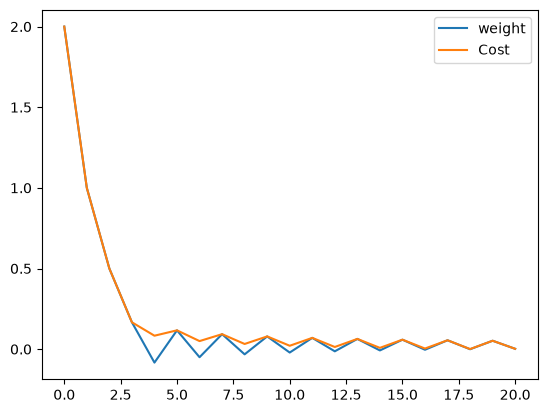

In [9]:
import autograd.numpy as np
import matplotlib.pyplot as plt

w = 2.0
max_its = 20
g = lambda w: np.abs(w)

#gradient descent with diminishing alpha
weight_history, cost_history = gradient_descent_diminishing_alpha(g, max_its, w)

plt.plot(weight_history, label="weight")
plt.plot(cost_history, label="Cost")
plt.legend()
plt.show()


# Exercise 3.9. Code up momentum-accelerated gradient descent

A skeleton of the desired algorithm is in the cell below.  All parts marked "TO DO" are for you to construct

In [16]:
from autograd import numpy as np
from autograd import value_and_grad 

# gradient descent function - inputs: g (input function), alpha (steplength parameter), max_its (maximum number of iterations), w (initialization)
def momentum(g,alpha,beta,max_its,w):
    # compute the gradient function of our input function - note this is a function too
    # that - when evaluated - returns both the gradient and function evaluations (remember
    # as discussed in Chapter 3 we always ge the function evaluation 'for free' when we use
    # an Automatic Differntiator to evaluate the gradient)
    gradient = value_and_grad(g)

    # run the gradient descent loop
    weight_history = []      # container for weight history
    cost_history = []        # container for corresponding cost function history
    alpha = 0
    cost_eval,grad_eval = gradient(w)
    
    # initialization for momentum direction
    h = np.zeros((w.shape))
    for k in range(1,max_its+1):        
        # evaluate the gradient, store current weights and cost function value
        cost_eval,grad_eval = gradient(w)
        weight_history.append(w)
        cost_history.append(cost_eval)
        
        #### momentum step - update exponential average of gradient directions to ameliorate zig-zagging ###
        ## TODO 

        # take gradient descent step
        w = w + alpha*h
            
    # collect final weights
    weight_history.append(w)
    # compute final cost function value via g itself (since we aren't computing 
    # the gradient at the final step we don't get the final cost function value 
    # via the Automatic Differentiatoor) 
    cost_history.append(g(w))  
    return weight_history,cost_history

Run momentum gradient descent to minimize the function described in the text.  Below a skeleton of the desired code is provided.  You will need to plot the cost function histories associated with each run to produce the final comparison.

In [ ]:
# define constants for a N=2 input quadratic
a1 = 0
b1 = 0*np.ones((2,1))
C1 = np.array([[0.5,0],[0,9.75]])

# a quadratic function defined using the constants above
g = lambda w: (a1 + np.dot(b1.T,w) + np.dot(np.dot(w.T,C1),w))[0]

w = np.array([10.0,1.0]); max_its = 25; alpha_choice = 10**(-1);
beta = 0
weight_history_1,cost_history_1 = momentum(g,alpha_choice,beta,max_its,w)

beta = 0.1;
weight_history_2,cost_history_2 = momentum(g,alpha_choice,beta,max_its,w)

beta = 0.7
weight_history_3,cost_history_3 = momentum(g,alpha_choice,beta,max_its,w)

$f$ has Lipschitz continuous gradient with constant $J$, and $g$
is Lipschitz continuous with constant $K$, so we can write for all
$\mathbf{x}$ and $\mathbf{y}$ in the domain of $g$\noindent 
\begin{equation}
\left\Vert \nabla f\left(g\left(\mathbf{x}\right)\right)-\nabla f\left(g\left(\mathbf{y}\right)\right)\right\Vert _{2}\leq J\left\Vert g\left(\mathbf{x}\right)-g\left(\mathbf{y}\right)\right\Vert _{2}\leq JK\left\Vert \mathbf{x}-\mathbf{y}\right\Vert _{2}.
\end{equation}

Therefore, $f\left(g\right)$ has Lipschitz continuous gradient with
constant $JK$. 